# Tahap 3 — Google Trends mingguan sebagai eksogen

Keputusan D5 memperlakukan Google Trends sebagai sinyal eksogen per merek yang
manfaatnya diuji melalui ablation di tahap berikutnya, bukan diasumsikan berguna.

In [1]:
from __future__ import annotations
from pathlib import Path
import json
import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

%matplotlib inline

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
CFG = yaml.safe_load((ROOT / "config.yaml").read_text(encoding="utf-8"))
SEED = int(CFG["seed"])
np.random.seed(SEED)

def rp(*parts: str) -> Path:
    """Resolve a repo-relative path (parts are path fragments under the repo root)."""
    return ROOT.joinpath(*parts)

BRAND_COLORS = {"OPPO": "#0072B2", "Realme": "#D55E00", "Samsung": "#009E73",
                "Vivo": "#CC79A7", "Xiaomi": "#E69F00"}
ALGO_COLORS = {"SARIMAX": "#0072B2", "RF": "#D55E00", "LSTM": "#009E73"}
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (9, 4.5),
                     "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 12})

Kalender kanonik berasal dari artefak Tahap 2. Sinyal Trends akan selalu
diselaraskan dan diperiksa terhadap grid Senin ini.

In [2]:
weekly = pd.read_parquet(rp("data", "interim", "weekly_store_brand.parquet"), columns=["week_start"])
week_grid = pd.DatetimeIndex(sorted(pd.to_datetime(weekly["week_start"]).unique()))
assert len(week_grid) == 184
assert (week_grid.dayofweek == 0).all(), "Kalender Tahap 2 harus ber-anchor Senin."
week_grid

DatetimeIndex(['2021-12-27', '2022-01-03', '2022-01-10', '2022-01-17',
               '2022-01-24', '2022-01-31', '2022-02-07', '2022-02-14',
               '2022-02-21', '2022-02-28',
               ...
               '2025-04-28', '2025-05-05', '2025-05-12', '2025-05-19',
               '2025-05-26', '2025-06-02', '2025-06-09', '2025-06-16',
               '2025-06-23', '2025-06-30'],
              dtype='datetime64[ns]', length=184, freq=None)

Berikut adalah logika Tahap 3 yang mandiri. Jalur `fetch_trends` hanya dipakai
bila pengambilan langsung diaktifkan secara eksplisit.

In [3]:
import logging
import time

logger = logging.getLogger(__name__)

GT_MIN, GT_MAX = 0.0, 100.0
MIN_COVERAGE = 0.95
_ALIGN_TOLERANCE = pd.Timedelta(days=3)
_FFILL_LIMIT = 1

COLUMNS = ["week_start", "brand", "gt_index"]


def align_to_grid(
    brand_series: pd.Series,
    week_grid: pd.DatetimeIndex,
    tolerance: pd.Timedelta = _ALIGN_TOLERANCE,
    ffill_limit: int = _FFILL_LIMIT,
) -> pd.Series:
    """Selaraskan satu deret GT ke grid mingguan Senin."""
    s = brand_series.sort_index()
    s = s[~s.index.duplicated(keep="last")]
    aligned = s.reindex(week_grid, method="nearest", tolerance=tolerance)
    if ffill_limit:
        aligned = aligned.ffill(limit=ffill_limit)
    return aligned


def _rescale_0_100(s: pd.Series) -> pd.Series:
    """Skala per merek ke [0,100] dengan membagi puncaknya."""
    peak = s.max()
    if not np.isfinite(peak) or peak <= 0:
        return s
    return (s / peak * GT_MAX).clip(GT_MIN, GT_MAX)


def fetch_trends(
    keywords_by_brand: dict[str, list[str]],
    timeframe: str,
    geo: str,
    week_grid: pd.DatetimeIndex,
    pause: float = 1.0,
) -> pd.DataFrame:
    """Ambil GT per merek via pytrends sebagai data long mingguan."""
    from pytrends.request import TrendReq

    pytrends = TrendReq(hl="id-ID", tz=420)
    frames: list[pd.DataFrame] = []
    for brand, keywords in keywords_by_brand.items():
        pytrends.build_payload(keywords, timeframe=timeframe, geo=geo)
        raw = pytrends.interest_over_time()
        if raw is None or raw.empty:
            raise RuntimeError(f"Google Trends kosong untuk merek {brand} ({keywords}).")
        if "isPartial" in raw.columns:
            raw = raw.drop(columns="isPartial")
        combined = _rescale_0_100(raw.mean(axis=1))
        aligned = align_to_grid(combined, week_grid)
        frames.append(
            pd.DataFrame({"week_start": week_grid, "brand": brand, "gt_index": aligned.values})
        )
        logger.info("GT fetched: %s (%d kata kunci)", brand, len(keywords))
        time.sleep(pause)
    return pd.concat(frames, ignore_index=True)[COLUMNS]


def fallback_trends(
    keywords_by_brand: dict[str, list[str]], week_grid: pd.DatetimeIndex
) -> pd.DataFrame:
    """Fallback in-memory dengan gt_index NaN untuk tiap minggu dan merek."""
    frames = [
        pd.DataFrame({"week_start": week_grid, "brand": brand, "gt_index": np.nan})
        for brand in keywords_by_brand
    ]
    return pd.concat(frames, ignore_index=True)[COLUMNS]


def coverage_by_brand(trends: pd.DataFrame, week_grid: pd.DatetimeIndex) -> pd.Series:
    """Fraksi minggu grid dengan gt_index non-NaN, per merek."""
    n = len(week_grid)
    return trends.groupby("brand")["gt_index"].apply(lambda s: s.notna().sum() / n)


def validate_trends(
    trends: pd.DataFrame, week_grid: pd.DatetimeIndex, min_coverage: float = MIN_COVERAGE
) -> dict:
    """Validasi DoD data GT nyata; fallback all-NaN tetap dapat dilaporkan."""
    vals = trends["gt_index"].dropna()
    in_range = bool(((vals >= GT_MIN) & (vals <= GT_MAX)).all()) if len(vals) else True
    cov = coverage_by_brand(trends, week_grid)
    expected_grid = pd.DatetimeIndex(week_grid).sort_values()
    calendar_by_brand = {}
    for brand, frame in trends.groupby("brand"):
        dates = pd.DatetimeIndex(pd.to_datetime(frame["week_start"]))
        dates_equal_week_grid = bool(dates.sort_values().equals(expected_grid))
        unique_week_start = bool(dates.is_unique)
        all_mondays = bool((dates.dayofweek == 0).all())
        calendar_by_brand[brand] = {
            "n_rows": len(frame),
            "dates_equal_week_grid": dates_equal_week_grid,
            "unique_week_start": unique_week_start,
            "all_mondays": all_mondays,
            "calendar_ok": bool(
                len(frame) == len(expected_grid)
                and dates_equal_week_grid
                and unique_week_start
                and all_mondays
            ),
        }
    calendar_ok = bool(
        len(calendar_by_brand)
        and all(status["calendar_ok"] for status in calendar_by_brand.values())
    )
    return {
        "n_rows": len(trends),
        "n_brands": trends["brand"].nunique(),
        "in_range": in_range,
        "min_coverage": float(cov.min()) if len(cov) else 0.0,
        "coverage_by_brand": {brand: round(float(value), 4) for brand, value in cov.items()},
        "min_coverage_ok": bool(len(cov) and cov.min() >= min_coverage),
        "calendar_ok": calendar_ok,
        "calendar_by_brand": calendar_by_brand,
    }

In [4]:
reference_calendar = pd.DataFrame(
    {"week_start": week_grid, "brand": "Merek uji", "gt_index": 50.0}
)
duplicate_calendar = reference_calendar.copy()
duplicate_calendar.loc[duplicate_calendar.index[-1], "week_start"] = week_grid[0]
shifted_calendar = reference_calendar.assign(week_start=lambda frame: frame["week_start"] + pd.Timedelta(days=1))
uneven_calendar = pd.concat(
    [reference_calendar, reference_calendar.iloc[:-1].assign(brand="Merek lain")],
    ignore_index=True,
)
for label, malformed in {
    "duplikat": duplicate_calendar,
    "bergeser/non-Senin": shifted_calendar,
    "jumlah per merek tidak seimbang": uneven_calendar,
}.items():
    malformed_stats = validate_trends(malformed, week_grid)
    assert "calendar_ok" in malformed_stats, (
        "validate_trends belum mengevaluasi kontrak kalender per merek."
    )
    assert not malformed_stats["calendar_ok"], f"Kalender {label} tidak ditolak."


def _read_cache(path: Path) -> pd.DataFrame:
    """Muat cache CSV bundled tanpa mengubah artefak sumber."""
    df = pd.read_csv(path, parse_dates=["week_start"])
    return df[COLUMNS]

Secara default notebook ini offline-only: cache bundled dimuat dan tidak pernah
ditulis. Pengambilan pytrends maupun penyimpanan hasil live harus diaktifkan
dengan dua sakelar lokal berikut.

In [5]:
FETCH_LIVE = False
SAVE_ARTIFACTS = False

keywords_by_brand = CFG["keywords_by_brand"]
cache_path = rp("data", "interim", "google_trends.csv")

if FETCH_LIVE:
    try:
        gt = fetch_trends(
            keywords_by_brand=keywords_by_brand,
            timeframe=CFG["trends_timeframe"],
            geo=CFG["trends_geo"],
            week_grid=week_grid,
        )
        source = "fetched"
    except Exception as exc:  # noqa: BLE001 - network, rate-limit, atau impor opsional
        logger.warning(
            "Fetch Google Trends GAGAL (%s: %s). Memakai fallback in-memory; cache tidak diubah.",
            type(exc).__name__,
            exc,
        )
        gt = fallback_trends(keywords_by_brand, week_grid)
        source = "fallback"
    if source == "fetched" and SAVE_ARTIFACTS:
        gt.to_csv(cache_path, index=False)
        logger.info("Cache GT live tersimpan: %s", cache_path)
else:
    gt = _read_cache(cache_path)
    source = "cache"

stats = validate_trends(gt, week_grid)
stats["source"] = source
gt.attrs["stats"] = stats

if source in {"cache", "fetched"}:
    assert stats["in_range"], "gt_index di luar [0,100]."
    assert stats["min_coverage_ok"], "Cakupan GT di bawah ambang D5."
    assert stats["calendar_ok"], "Kalender GT per merek tidak identik dengan grid Tahap 2."

gt.attrs["stats"]

{'n_rows': 920,
 'n_brands': 5,
 'in_range': True,
 'min_coverage': 1.0,
 'coverage_by_brand': {'OPPO': 1.0,
  'Realme': 1.0,
  'Samsung': 1.0,
  'Vivo': 1.0,
  'Xiaomi': 1.0},
 'min_coverage_ok': True,
 'calendar_ok': True,
 'calendar_by_brand': {'OPPO': {'n_rows': 184,
   'dates_equal_week_grid': True,
   'unique_week_start': True,
   'all_mondays': True,
   'calendar_ok': True},
  'Realme': {'n_rows': 184,
   'dates_equal_week_grid': True,
   'unique_week_start': True,
   'all_mondays': True,
   'calendar_ok': True},
  'Samsung': {'n_rows': 184,
   'dates_equal_week_grid': True,
   'unique_week_start': True,
   'all_mondays': True,
   'calendar_ok': True},
  'Vivo': {'n_rows': 184,
   'dates_equal_week_grid': True,
   'unique_week_start': True,
   'all_mondays': True,
   'calendar_ok': True},
  'Xiaomi': {'n_rows': 184,
   'dates_equal_week_grid': True,
   'unique_week_start': True,
   'all_mondays': True,
   'calendar_ok': True}},
 'source': 'cache'}

Cakupan penuh pada kalender kanonik dan bentuk indeks per merek ditampilkan
untuk audit sinyal eksogen sebelum digunakan oleh tahap pemodelan.

In [6]:
coverage_by_brand(gt, week_grid).rename("cakupan")

brand
OPPO       1.0
Realme     1.0
Samsung    1.0
Vivo       1.0
Xiaomi     1.0
Name: cakupan, dtype: float64

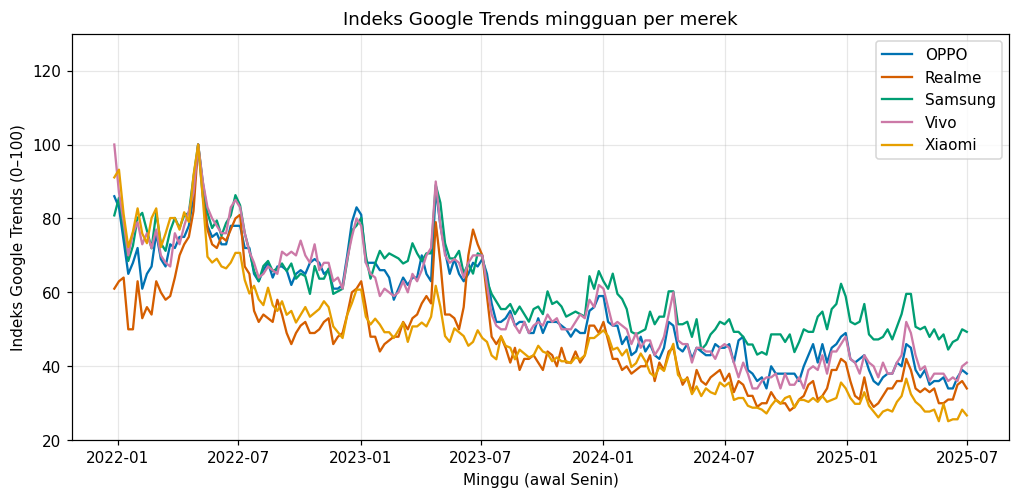

In [7]:
fig, ax = plt.subplots(figsize=(11, 4.8))
for brand in sorted(gt["brand"].unique()):
    brand_gt = gt.loc[gt["brand"].eq(brand)].sort_values("week_start")
    ax.plot(brand_gt["week_start"], brand_gt["gt_index"], label=brand, color=BRAND_COLORS[brand])
ax.set_title("Indeks Google Trends mingguan per merek")
ax.set_xlabel("Minggu (awal Senin)")
ax.set_ylabel("Indeks Google Trends (0–100)")
ax.set_ylim(20, 130)
ax.legend(loc="upper right")
plt.show()

In [8]:
assert gt.attrs["stats"]["calendar_ok"], gt.attrs["stats"]["calendar_by_brand"]
assert gt.groupby("brand").size().eq(len(week_grid)).all()
assert gt.groupby("brand")["week_start"].apply(
    lambda dates: pd.DatetimeIndex(dates).sort_values().equals(week_grid)
).all()
assert (gt["week_start"].dt.dayofweek == 0).all()
assert {"week_start", "brand", "gt_index"}.issubset(gt.columns), gt.columns.tolist()
assert gt["brand"].nunique() == 5
assert len(gt) == 5 * 184, len(gt)
assert gt["gt_index"].between(0, 100).all()
print(f"✅ Tahap 3: GT {len(gt)} baris (5 merek × 184 minggu), gt_index ∈ [0,100]")

✅ Tahap 3: GT 920 baris (5 merek × 184 minggu), gt_index ∈ [0,100]
